In [3]:
import rasterio
from rasterio.enums import Resampling
from rasterio.warp import calculate_default_transform, reproject
from rasterio.transform import from_origin
import numpy as np
import geopandas as gpd
from shapely.geometry import Point
from shapely.geometry import box
import random
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
from scipy.stats import pearsonr
from rasterio.transform import rowcol
from sklearn.metrics import r2_score
import pandas as pd
import numpy as np
import rioxarray as rxr
import matplotlib as mpl
from Auxiliary_function import *
mpl.rcParams['font.family'] = 'Arial'

c:\Users\minyu\.conda\envs\ICESAT_env\lib\site-packages\cupy\_environment.py:215: UserWarning: CUDA path could not be detected. Set CUDA_PATH environment variable if CuPy fails to load.
  warnings.warn(


In [2]:
year = 2019
validation_sample_path = f'E:/UK_situ/Survey/shp_by_year6/profile_agg_30m_centerpoint_{year}.shp'
k = gpd.read_file(validation_sample_path)
k.columns

Index(['row', 'col', 'mean_val', 'pt_count', 'std', 'median_v', 'min', 'max',
       'UK_DEM_201', 'geometry'],
      dtype='object')

In [15]:

def ICESAT_Refined(validation_point_path, refer_name, band,std, mask_apply, oh_mask, Freq_mask, output_to_new_shp ,oh_mask1, Freq_mask1, rename ,display=True):

    # a = gpd.read_file(ICESat_path)

    gdf = gpd.read_file(validation_point_path)

    # ======================
    # 2. 严格筛选（安全写法）
    # ======================
    z = gdf.dropna(subset=[refer_name, band])

    a = z[
        (z[refer_name] != 0) &
        (z[band] != 0) &
        (z[refer_name] != -999) &
        (z[band] != -999) &
        (z[refer_name] != 6) &
        (z[band] != 6) &
        (z[refer_name] < 6) &
        (z[band] > -5) 
        # &(z['std'] < std)
    ]
    
    # ======================
    # 2. 指标
    # ======================

    if mask_apply:
        mask = (a[refer_name] > oh_mask[0]) & (a[band] < Freq_mask[0]) 
        for j in range(1 ,len(oh_mask)):
            mask = mask | ((a[refer_name] > oh_mask[j]) & (a[band] < Freq_mask[j]))
        
        mask = mask | (a[refer_name] < oh_mask1[0]) & (a[band] > Freq_mask1[0])
        for j in range(1 ,len(oh_mask1)):
            mask = mask | (a[refer_name] < oh_mask1[j]) & (a[band] > Freq_mask1[j])
        # mask = mask | (a['OH'] < -2)
        a = a[~mask]

    x = a[refer_name].values
    y = a[band].values

    diff = y - x
    R2 = r2_score(x, y)
    MAE = np.mean(np.abs(diff))
    RMSE = np.sqrt(np.mean(diff**2))
    num = len(x)


    
    N = len(x)

    if N > 5000:
        idx_sample = np.random.choice(N, 5000, replace=False)
    else:
        idx_sample = np.arange(N)

    xy_sample = np.vstack([x[idx_sample], y[idx_sample]])
    kde = gaussian_kde(xy_sample)

    # ⭐ 对所有点计算密度（关键技巧）
    xy_all = np.vstack([x, y])
    z_density = kde(xy_all)

    # ======================
    # 4. 排序（保证视觉效果）
    # ======================
    idx = z_density.argsort()
    x = x[idx]
    y = y[idx]
    z = z_density[idx]

    
    if mask_apply & output_to_new_shp:
        p = Path(validation_point_path)
        new_p = p.with_name(p.stem + rename + p.suffix)
        print(f'New files output to {new_p}')
        a.to_file(new_p)

    if display:

        fig, ax = plt.subplots(figsize=(6, 6))

        sc = ax.scatter(
            x, y,
            c=z,
            s=8,
            cmap='Spectral_r',
            edgecolor='none'
        )

        # plt.title(f'{region}_{year}', fontsize=16)

        if band == band:
            limsx = [-4, 6]
            limsy = [-4, 6]
            ax.plot(limsx, limsy, 'r--', linewidth=1)
            ax.set_xlim(limsx)
            ax.set_xticks(np.arange(limsx[0], limsx[1] + 0.001, 1))
            ax.set_ylim(limsy)
            ax.set_yticks(np.arange(limsy[0], limsy[1] + 0.001, 1))
        # textstr = f'num = {len(a)}'
        textstr = f"R² = {R2:.2f}\nMAE = {MAE:.2f}\nRMSE = {RMSE:.2f}\nN = {num}"
        ax.text(
            0.05, 0.95, textstr,
            transform=ax.transAxes,   # 使用轴坐标系
            fontsize=16,
            verticalalignment='top',
            horizontalalignment='left',
            bbox=dict(facecolor='white', alpha=0.7, edgecolor='none')
        )

        ax.grid(
            True,
            which='both',
            linestyle='--',
            linewidth=0.6,
            color='gray',
            alpha=0.6
        )
        plt.tight_layout()
        plt.show()

In [2]:
def draw_validation_plot2(
    refer_name,
    validation_point_path,
    retrieved_DTM_name,
    std_std,
    output_path,
    name,
    xy_lim_range,
    vmax,
    kde_sample_size=5000   # ⭐关键参数
):

    # ======================
    # 1. 读取 + 筛选
    # ======================
    gdf = gpd.read_file(validation_point_path)

    # ======================
    # 2. 严格筛选（安全写法）
    # ======================
    #z = gdf.dropna(subset=[refer_name, retrieved_DTM_name, 'std'])
    z = gdf.dropna(subset=[refer_name, retrieved_DTM_name])

    z = z[
        (z[refer_name] != 0) &
        (z[retrieved_DTM_name] != 0) &
        (z[refer_name] != -999) &
        (z[retrieved_DTM_name] != -999) &
        (z[refer_name] != 6) &
        (z[retrieved_DTM_name] != 6) &
        (z[refer_name] < 6) &
        (z[retrieved_DTM_name] > -5) 
        #&(z['std'] < std_std)
    ]


    x = z[refer_name].values
    y = z[retrieved_DTM_name].values

    # ======================
    # 2. 指标
    # ======================
    diff = y - x
    R2 = r2_score(x, y)
    MAE = np.mean(np.abs(diff))
    RMSE = np.sqrt(np.mean(diff**2))
    num = len(x)

    print(f"R²={R2:.3f}, MAE={MAE:.3f}, RMSE={RMSE:.3f}, N={num}")

    # ======================
    # 3. KDE（只用子样本）
    # ======================
    N = len(x)

    if N > kde_sample_size:
        idx_sample = np.random.choice(N, kde_sample_size, replace=False)
    else:
        idx_sample = np.arange(N)

    xy_sample = np.vstack([x[idx_sample], y[idx_sample]])

    kde = gaussian_kde(xy_sample)

    # ⭐ 对所有点计算密度（关键技巧）
    xy_all = np.vstack([x, y])
    z_density = kde(xy_all)

    # ======================
    # 4. 排序（保证视觉效果）
    # ======================
    idx = z_density.argsort()
    x_sorted = x[idx]
    y_sorted = y[idx]
    z_sorted = z_density[idx]

    # ======================
    # 5. 绘图
    # ======================
    fig, ax = plt.subplots()

    sc = ax.scatter(
        x_sorted,
        y_sorted,
        c=z_sorted,
        s=5,
        cmap='Spectral_r',
        vmin=0,
        vmax=vmax
    )

    cbar = plt.colorbar(sc)
    cbar.ax.tick_params(labelsize=14)

    xmin, xmax = xy_lim_range[0], xy_lim_range[1]

    # 1:1线
    ax.plot([xmin, xmax], [xmin, xmax], '--', color='gray', linewidth=0.8)

    # 文本
    textstr = f"R² = {R2:.2f}\nMAE = {MAE:.2f}\nRMSE = {RMSE:.2f}\nN = {num}"
    ax.text(0.55, 0.05, textstr, transform=ax.transAxes, fontsize=20)
    ax.text(0.05, 0.90, name, transform=ax.transAxes, fontsize=20)

    # 坐标轴
    ax.set_xlabel('Airborne LiDAR DEM', fontsize=18)
    ax.set_ylabel('Reconstructed DEM', fontsize=18)

    ax.set_xlim(xmin, xmax)
    ax.set_ylim(xmin, xmax)

    ticks = np.arange(xmin, xmax + xy_lim_range[2], xy_lim_range[2])
    ax.set_xticks(ticks)
    ax.set_yticks(ticks)
    ax.tick_params(labelsize=16)

    plt.show()
    # plt.savefig(output_path, dpi=300, bbox_inches='tight')
    # plt.close()

    print("绘图完成！")
    
    return z

Index(['DEM_rec', 'median_v', 'DEM_ref_co', 'geometry'], dtype='object')
R²=0.951, MAE=0.199, RMSE=0.391, N=47045


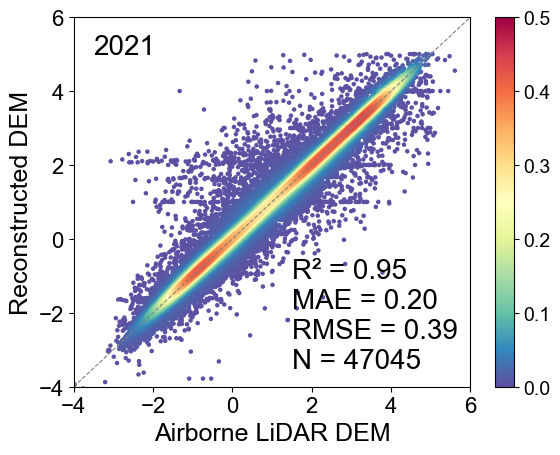

绘图完成！


In [35]:
year = 2021
path = f'E:/UK_situ/Shp_data/profile_agg_30m_centerpoint_2021_merged_q_refined.shp'
path = 'H:\ICESat-2\Validation_all_lidar\merged_in_situ_samples_.shp'
# path = f'E:/UK_situ/Shp_data/profile_agg_30m_centerpoint_2024.shp'
a = gpd.read_file(path)
print(a.columns)

# path = 'H:\ICESat-2\Validation_all_lidar\merged_in_situ_samples_.shp'
# a = gpd.read_file(path)
# print(a.columns)
# year = 2020
# path =f'E:/UK_situ/Shp_data/profile_agg_30m_centerpoint_2021_merged_q.shp'
# a = gpd.read_file(path)
#a = draw_validation_plot2('median_v' ,path, 'DEM_ref1',1, f'E:/UK_situ/all_{year}a.jpg', f'{year}', [-4, 6, 2], 0.5)
# a = draw_validation_plot2('median_v' ,path, 'DEM_ref_co',1, f'E:/UK_situ/all_{year}a.jpg', f'{year}', [-4, 6, 2], 0.5)
a = draw_validation_plot2('median_v' ,path, 'DEM_ref_co',1, f'E:/UK_situ/all_{year}a.jpg', f'{year}', [-4, 6, 2], 0.5)

In [6]:
year = 2021
path = f'E:/UK_situ/Shp_data/profile_agg_30m_centerpoint_2021_merged_q.shp'
# path = f'E:/UK_situ/Shp_data/profile_agg_30m_centerpoint_2024.shp'
a = gpd.read_file(path)
print(a.columns)


Index(['row', 'col', 'mean_val', 'pt_count', 'std', 'median_v', 'min', 'max',
       'UK_DEM_202', 'DEM_ref_co', 'geometry'],
      dtype='object')


In [4]:
path = 'H:\ICESat-2\Validation_all_lidar\merged_in_situ_samples.shp'
a = gpd.read_file(path)
print(a.columns)

Index(['DEM_rec', 'median_v', 'DEM_ref_co', 'geometry'], dtype='object')


In [ ]:
year = 2024
# validation_sample_path = f'E:/UK_situ/Survey/shp_by_year6/profile_agg_30m_centerpoint_{year}.shp'
# # validation_sample_path = f'E:/UK_situ/Shp_data/profile_agg_30m_centerpoint_{year}_refined.shp'
# validation_sample_path = f'E:/UK_situ/Shp_data/profile_agg_30m_centerpoint_{year}_merged_.shp'
# validation_sample_path = f'E:/UK_situ/Shp_data/profile_agg_30m_centerpoint_{year}.shp'
validation_sample_path = 'H:\ICESat-2\Validation_all_lidar\merged_in_situ_samples.shp'
a = gpd.read_file(validation_sample_path)
print(a.columns)
z = draw_validation_plot2('median_v' ,validation_sample_path, 'DEM_rec',1, f'E:/UK_situ/all_{year}a.jpg', f'{year}', [-4, 6, 2], 0.5)

In [34]:
gdf_list = []
validation_sample_paths_2019 = f'E:/UK_situ/Shp_data/profile_agg_30m_centerpoint_2019_merged_.shp'
validation_sample_paths_2020 = f'E:/UK_situ/Shp_data/profile_agg_30m_centerpoint_2020_merged_.shp'
validation_sample_paths_2021 = f'E:/UK_situ/Shp_data/profile_agg_30m_centerpoint_2021_merged_q_refined.shp'
validation_sample_paths_2022 = f'E:/UK_situ/Shp_data/profile_agg_30m_centerpoint_2022_merged_.shp'
validation_sample_paths_2023 = f'E:/UK_situ/Shp_data/profile_agg_30m_centerpoint_2023_merged_.shp'
validation_sample_paths_2024 = f'E:/UK_situ/Shp_data/profile_agg_30m_centerpoint_2024.shp'
validation_sample_paths_all = [validation_sample_paths_2019, validation_sample_paths_2020,
                               validation_sample_paths_2021, validation_sample_paths_2022,
                               validation_sample_paths_2023, validation_sample_paths_2024]


target_crs = "EPSG:32630"   # WGS84 / UTM zone 30N

gdf_list = []

for path in validation_sample_paths_all:

    gdf = gpd.read_file(path)

    if path == validation_sample_paths_2019:
        gdf['DEM_rec'] = gdf['UK_DEM_201']
    else:
        gdf['DEM_rec'] = gdf['UK_DEM_202']
    gdf = gdf[['DEM_rec', 'median_v', 'DEM_ref_co', 'geometry']]
    # 转换到统一投影
    gdf = gdf.to_crs(target_crs)

    gdf_list.append(gdf)

merged_gdf = gpd.GeoDataFrame(
    pd.concat(gdf_list, ignore_index=True),
    crs=target_crs
)

# =========================

output_path = fr'H:\ICESat-2\Validation_all_lidar\merged_in_situ_samples_.shp'

merged_gdf.to_file(output_path)

print('Merged shapefile saved to:')
print(output_path)


# for validation_sample_paths  in validation_sample_paths_all:
#     for path in validation_sample_paths:
        
#         gdf = gpd.read_file(path)
#         gdf_selected = gdf[['Refer_dem', 'DEM_new9']]  # 只保留所需字段
#         gdf_list.append(gdf_selected)
# # 合并所有 GeoDataFrame
# merged_gdf = pd.concat(gdf_list, ignore_index=True)


Merged shapefile saved to:
H:\ICESat-2\Validation_all_lidar\merged_in_situ_samples_.shp


Index(['Refer_dem', 'retrieved_', 'AAA', 'SY', 'DEM_new9', 'Refer_dem_',
       'DEM_new9_3', 'DEM9_SY', 'DEM_new9_', 'geometry'],
      dtype='object')
R²=0.906, MAE=0.257, RMSE=0.359, N=8521


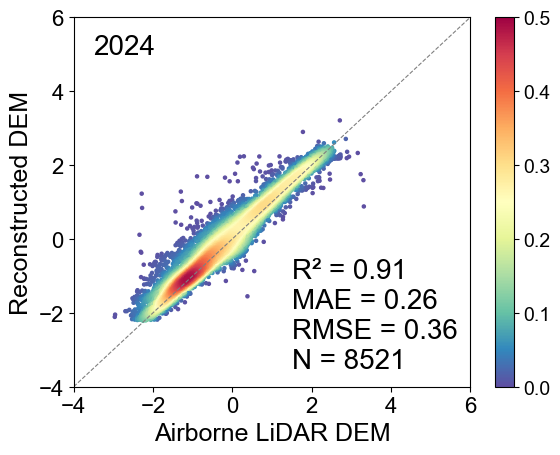

绘图完成！


In [77]:
year = 2024
validation_sample_path = f'H:\ICESat-2\Validation_all_lidar\merged_validation_samples_{year}.shp'

a = gpd.read_file(validation_sample_path)
print(a.columns)
z = draw_validation_plot2('Refer_dem' ,validation_sample_path, 'DEM_new9',1, f'E:/UK_situ/all_{year}a.jpg', f'{year}', [-4, 6, 2], 0.5)

New files output to E:\UK_situ\Shp_data\profile_agg_30m_centerpoint_2021_merged_q_refined.shp


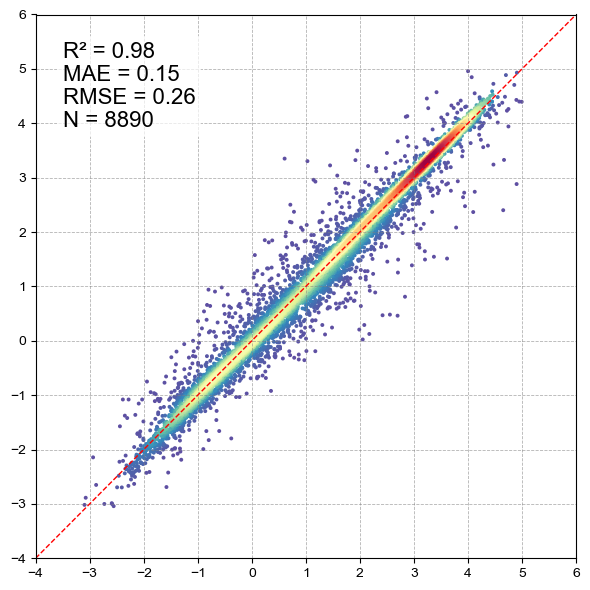

In [30]:

year = 2021
path = f'E:/UK_situ/Shp_data/profile_agg_30m_centerpoint_2021_merged_q.shp'
# path = f'E:/UK_situ/Shp_data/profile_agg_30m_centerpoint_{year}.shp'

ICESAT_Refined(validation_point_path = path,
               refer_name= 'median_v',
               band = 'DEM_ref_co',
               std= 1,
               mask_apply = True,  #False True
               oh_mask   = [3],
               Freq_mask = [1],
               output_to_new_shp=True,
               oh_mask1 =   [0.5, 0, -1, -2, -1.5, -2.5, 2.5],
               Freq_mask1 = [2, 1, 0, -1, -0.5, -2, 3.5],
               rename= '_refined'
               )

In [ ]:
year = 2019
path = f'E:/UK_situ/Survey/shp_by_year6/profile_agg_30m_centerpoint_{year}_.shp'
path = f'E:/UK_situ/Shp_data/profile_agg_30m_centerpoint_{year}.shp'

In [285]:
import geopandas as gpd

# Define paths
year = 2022
path1 = f'E:/UK_situ/Survey/shp_by_year6/profile_agg_30m_centerpoint_{year}__refined.shp'
path2 = f'E:/UK_situ/Shp_data/profile_agg_30m_centerpoint_{year}_refined.shp'

# Read both shapefiles
gdf1 = gpd.read_file(path1)
gdf2 = gpd.read_file(path2)

# Check if both have the same coordinate reference system (CRS)
# If not, you may need to reproject one to match the other
if gdf1.crs != gdf2.crs:
    gdf2 = gdf2.to_crs(gdf1.crs)  # reproject gdf2 to gdf1's CRS

# Concatenate the two GeoDataFrames
merged_gdf = gpd.GeoDataFrame(pd.concat([gdf1, gdf2], ignore_index=True), crs=gdf1.crs)

# Save to a new shapefile
output_path = f'E:/UK_situ/Shp_data/profile_agg_30m_centerpoint_{year}_merged_.shp'
merged_gdf.to_file(output_path)

print(f"Merged shapefile saved to: {output_path}")

Merged shapefile saved to: E:/UK_situ/Shp_data/profile_agg_30m_centerpoint_2022_merged_.shp


In [8]:
def draw_validation_plot(
    refer_name,
    validation_point_path,
    retrieved_DTM_name,
    std_std,
    output_path,
    name,
    xy_lim_range,
    vmax,
    kde_sample_size=5000   # ⭐关键参数
):

    # ======================
    # 1. 读取 + 筛选
    # ======================
    gdf = gpd.read_file(validation_point_path)

    # ======================
    # 2. 严格筛选（安全写法）
    # ======================
    z = gdf.dropna(subset=[refer_name, retrieved_DTM_name])

    z = z[
        (z[refer_name] != 0) &
        (z[retrieved_DTM_name] != 0) &
        (z[refer_name] != -999) &
        (z[retrieved_DTM_name] != -999) &
        (z[refer_name] != 6) &
        (z[retrieved_DTM_name] != 6) &
        (z[refer_name] < 6) &
        (z[retrieved_DTM_name] > -5) 
    ]


    x = z[refer_name].values
    y = z[retrieved_DTM_name].values

    # ======================
    # 2. 指标
    # ======================
    diff = y - x
    # R2 = r2_score(x, y)
    R2, _ = pearsonr(x, y)
    MAE = np.mean(np.abs(diff))
    RMSE = np.sqrt(np.mean(diff**2))
    num = len(x)

    print(f"R²={R2:.3f}, MAE={MAE:.3f}, RMSE={RMSE:.3f}, N={num}")

    # ======================
    # 3. KDE（只用子样本）
    # ======================
    N = len(x)

    if N > kde_sample_size:
        idx_sample = np.random.choice(N, kde_sample_size, replace=False)
    else:
        idx_sample = np.arange(N)

    xy_sample = np.vstack([x[idx_sample], y[idx_sample]])

    kde = gaussian_kde(xy_sample)

    # ⭐ 对所有点计算密度（关键技巧）
    xy_all = np.vstack([x, y])
    z_density = kde(xy_all)

    # ======================
    # 4. 排序（保证视觉效果）
    # ======================
    idx = z_density.argsort()
    x_sorted = x[idx]
    y_sorted = y[idx]
    z_sorted = z_density[idx]

    # ======================
    # 5. 绘图
    # ======================
    fig, ax = plt.subplots()

    sc = ax.scatter(
        x_sorted,
        y_sorted,
        c=z_sorted,
        s=5,
        cmap='Spectral_r',
        vmin=0,
        vmax=vmax
    )

    cbar = plt.colorbar(sc)
    cbar.ax.tick_params(labelsize=14)

    xmin, xmax = xy_lim_range[0], xy_lim_range[1]

    # 1:1线
    ax.plot([xmin, xmax], [xmin, xmax], '--', color='gray', linewidth=0.8)

    # 文本
    #textstr = f"R² = {R2:.2f}\nMAE = {MAE:.2f}\nRMSE = {RMSE:.2f}\nN = {num}"
    textstr = f"R = {R2:.2f}\nN = {num}"
    ax.text(0.52, 0.05, textstr, transform=ax.transAxes, fontsize=20)
    ax.text(0.03, 0.90, name, transform=ax.transAxes, fontsize=20)

    # 坐标轴
    ax.set_xlabel('Refined ICESat-2', fontsize=18)
    ax.set_ylabel('NAEF', fontsize=18)

    ax.set_xlim(xmin, xmax)
    ax.set_ylim(xmin, xmax)
    ax.set_ylim(0, 1)
    
    ticks = np.arange(xmin, xmax + xy_lim_range[2], xy_lim_range[2])
    ax.set_xticks(ticks)
    # ax.set_yticks(ticks)
    ax.tick_params(labelsize=16)

    plt.show()
    # plt.savefig(output_path, dpi=300, bbox_inches='tight')
    # plt.close()

    print("绘图完成！")
    
    return z

In [18]:
def draw_validation_plot(
    refer_name,
    validation_point_path,
    retrieved_DTM_name,
    std_std,
    output_path,
    name,
    xy_lim_range,
    xy_lim_range2,
    vmax,
    kde_sample_size=5000
):

    import geopandas as gpd
    import numpy as np
    import matplotlib.pyplot as plt
    from scipy.stats import gaussian_kde, pearsonr

    # ======================
    # 1. 读取 + 筛选
    # ======================
    gdf = gpd.read_file(validation_point_path)

    z = gdf.dropna(subset=[refer_name, retrieved_DTM_name])

    z = z[
        (z[refer_name] != 0) &
        (z[retrieved_DTM_name] != 0) &
        (z[refer_name] != -999) &
        (z[retrieved_DTM_name] != -999) &
        (z[refer_name] != 6) &
        (z[retrieved_DTM_name] != 6) &
        (z[refer_name] < 6) &
        (z[retrieved_DTM_name] > -5)
    ]

    x = z[refer_name].values
    y = z[retrieved_DTM_name].values

    # ======================
    # 2. 指标
    # ======================
    diff = y - x
    R, _ = pearsonr(x, y)
    MAE = np.mean(np.abs(diff))
    RMSE = np.sqrt(np.mean(diff**2))
    num = len(x)

    print(f"R={R:.3f}, MAE={MAE:.3f}, RMSE={RMSE:.3f}, N={num}")

    # ======================
    # 3. KDE（子样本）
    # ======================
    N = len(x)

    if N > kde_sample_size:
        idx_sample = np.random.choice(N, kde_sample_size, replace=False)
    else:
        idx_sample = np.arange(N)

    xy_sample = np.vstack([x[idx_sample], y[idx_sample]])
    kde = gaussian_kde(xy_sample)

    xy_all = np.vstack([x, y])
    z_density = kde(xy_all)

    # 排序（提升视觉效果）
    idx = z_density.argsort()
    x_sorted = x[idx]
    y_sorted = y[idx]
    z_sorted = z_density[idx]

    # ======================
    # 4. 绘图
    # ======================
    fig, ax = plt.subplots()

    sc = ax.scatter(
        x_sorted,
        y_sorted,
        c=z_sorted,
        s=5,
        cmap='Spectral_r',
        vmin=0,
        vmax=vmax
    )

    cbar = plt.colorbar(sc)
    cbar.ax.tick_params(labelsize=14)

    xmin, xmax = xy_lim_range[0], xy_lim_range[1]

    # ======================
    # ⭐ 拟合线（替换对角线）
    # ======================
    coef = np.polyfit(x, y, 1)
    k, b = coef

    x_fit = np.linspace(xmin, xmax, 200)
    y_fit = k * x_fit + b

    ax.plot(x_fit, y_fit, color='red', linewidth=1.5)

    # ======================
    # 文本
    # ======================
    textstr = f"R = {R:.2f}\nN = {num}"
    textstr = f"R={R:.3f}\nMAE={MAE:.3f}\nRMSE={RMSE:.3f}\nN={num}"
    ax.text(0.65, 0.05, textstr, transform=ax.transAxes, fontsize=20)

    ax.text(0.03, 0.90, name, transform=ax.transAxes, fontsize=20)

    # ⭐ 拟合公式
    fit_text = f"y = {k:.2f}x + {b:.2f}"
    ax.text(0.03, 0.8, fit_text, transform=ax.transAxes,
            fontsize=16, color='red')

    # ======================
    # 坐标轴
    # ======================
    ax.set_xlabel('in-situ profile', fontsize=18)
    ax.set_ylabel('Retrieval DEM', fontsize=18)


    ax.set_xlim(xmin, xmax)
    ax.set_ylim(xmin, xmax)
    ax.set_ylim(xy_lim_range2[0],xy_lim_range2[1])
    
    ticks = np.arange(xmin, xmax + xy_lim_range[2], xy_lim_range[2])
    ticks2 = np.arange(xy_lim_range2[0], xy_lim_range2[1]+xy_lim_range2[2], xy_lim_range2[2])
    ax.set_xticks(ticks)
    ax.set_yticks(ticks2)
    ax.tick_params(labelsize=16)

    plt.show()
    # plt.savefig(output_path, dpi=300, bbox_inches='tight')
    # plt.close()

    print("绘图完成！")

    return z

Index(['Unnamed_ 0', 'distance', 'mean_heigh', 'mean_lon', 'mean_lat', 'OSGM',
       'OH', 'Strip_No', 'b1_FB6', 'b2_FB6', 'b3_FB6', 'b4_FB6', 'b5_FB6',
       'b6_FB6', 'b7_FB6', 'Ref_dem', 'Re_dem', 'LULC', 'geometry'],
      dtype='object')
R=-0.697, MAE=1.707, RMSE=2.035, N=7288


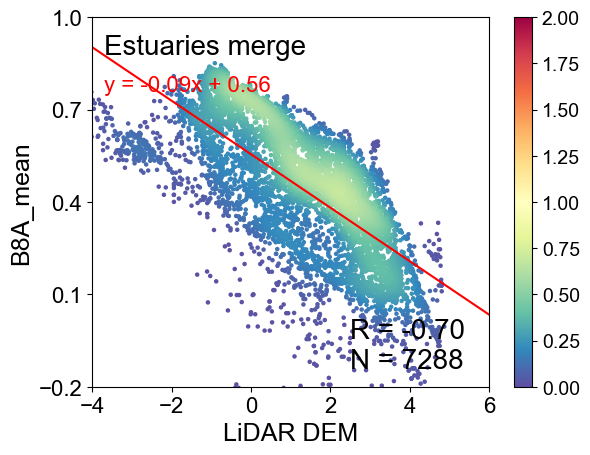

绘图完成！


In [4]:
path = 'H:/ICESat-2/Region1_map/Thames_map/A2022/A_Thames_30m_2022_new10_valid_kk.shp'
path = 'H:/ICESat-2/Region4_map/Morecambe_map/A2023/A_Morecambe_30m_2023_new10_valid_kk.shp'
path = 'H:/ICESat-2/Region4_map/Severn_map/A2020/A_Severn_30m_2020_new10_valid_kk.shp'
path = 'E:/Paper4_revision/TMS_ICESAT_Merged.shp'
a = gpd.read_file(path)
print(a.columns)
year = 2019
# z = draw_validation_plot2('median_v' ,path, 'UK_DEM_202',1, f'E:/UK_situ/all_{year}a.jpg', f'all {year}', [-4, 6, 2], 0.5)
z = draw_validation_plot('Ref_dem' ,path, 'b4_FB6', 1, f'E:/UK_situ/all_{year}a.jpg', f'Estuaries merge', [-4, 6, 2],[-0.2, 1, 0.3],2)

In [522]:
import geopandas as gpd

# Define paths

path1 = 'H:/ICESat-2/Region1_map/Thames_map/A2022/A_Thames_30m_2022_new10_valid_kk.shp'
path2 = 'H:/ICESat-2/Region4_map/Morecambe_map/A2023/A_Morecambe_30m_2023_new10_valid_kk.shp'
path3 = 'H:/ICESat-2/Region4_map/Severn_map/A2020/A_Severn_30m_2020_new10_valid_kk.shp'

# Read both shapefiles
gdf1 = gpd.read_file(path1)
gdf2 = gpd.read_file(path2)
gdf3 = gpd.read_file(path3)

# Check if both have the same coordinate reference system (CRS)
# If not, you may need to reproject one to match the other
if gdf1.crs != gdf2.crs:
    gdf2 = gdf2.to_crs(gdf1.crs)  # reproject gdf2 to gdf1's CRS
    
if gdf1.crs != gdf3.crs:
    gdf3 = gdf3.to_crs(gdf1.crs)

# Concatenate the two GeoDataFrames
merged_gdf = gpd.GeoDataFrame(pd.concat([gdf1, gdf2, gdf3], ignore_index=True), crs=gdf1.crs)

# Save to a new shapefile
output_path = f'E:/Paper4_revision/TMS_ICESAT_Merged.shp'
merged_gdf.to_file(output_path)

print(f"Merged shapefile saved to: {output_path}")

Merged shapefile saved to: E:/Paper4_revision/TMS_ICESAT_Merged.shp


In [1]:
def draw_validation_plot(
    refer_name,
    validation_point_path,
    retrieved_DTM_name,
    std_std,
    output_path,
    name,
    xy_lim_range,
    xy_lim_range2,
    vmax,
    kde_sample_size=5000
):

    import geopandas as gpd
    import numpy as np
    import matplotlib.pyplot as plt
    from scipy.stats import gaussian_kde, pearsonr

    # ======================
    # 1. 读取 + 筛选
    # ======================
    gdf = gpd.read_file(validation_point_path)

    z = gdf.dropna(subset=[refer_name, retrieved_DTM_name])

    z = z[
        (z[refer_name] != 0) &
        (z[retrieved_DTM_name] != 0) &
        (z[refer_name] != -999) &
        (z[retrieved_DTM_name] != -999) &
        (z[refer_name] != 6) &
        (z[retrieved_DTM_name] != 6) &
        (z[refer_name] < 6) &
        (z[retrieved_DTM_name] > -5)
    ]

    x = z[refer_name].values
    y = z[retrieved_DTM_name].values

    # ======================
    # 2. 指标
    # ======================
    diff = y - x
    R, _ = pearsonr(x, y)
    MAE = np.mean(np.abs(diff))
    RMSE = np.sqrt(np.mean(diff**2))
    num = len(x)

    print(f"R={R:.3f}, MAE={MAE:.3f}, RMSE={RMSE:.3f}, N={num}")

    # ======================
    # 3. KDE（子样本）
    # ======================
    N = len(x)

    if N > kde_sample_size:
        idx_sample = np.random.choice(N, kde_sample_size, replace=False)
    else:
        idx_sample = np.arange(N)

    xy_sample = np.vstack([x[idx_sample], y[idx_sample]])
    kde = gaussian_kde(xy_sample)

    xy_all = np.vstack([x, y])
    z_density = kde(xy_all)

    # 排序（提升视觉效果）
    idx = z_density.argsort()
    x_sorted = x[idx]
    y_sorted = y[idx]
    z_sorted = z_density[idx]

    # ======================
    # 4. 绘图
    # ======================
    fig, ax = plt.subplots()

    sc = ax.scatter(
        x_sorted,
        y_sorted,
        c=z_sorted,
        s=5,
        cmap='Spectral_r',
        vmin=0,
        vmax=vmax
    )

    cbar = plt.colorbar(sc)
    cbar.ax.tick_params(labelsize=14)

    xmin, xmax = xy_lim_range[0], xy_lim_range[1]

    # ======================
    # ⭐ 拟合线（替换对角线）
    # ======================
    coef = np.polyfit(x, y, 1)
    k, b = coef

    x_fit = np.linspace(xmin, xmax, 200)
    y_fit = k * x_fit + b

    ax.plot(x_fit, y_fit, color='red', linewidth=1.5)

    # ======================
    # 文本
    # ======================
    textstr = f"R = {R:.2f}\nN = {num}"
    textstr = f"R={R:.3f}\nMAE={MAE:.3f}\nRMSE={RMSE:.3f}\nN={num}"
    ax.text(0.55, 0.05, textstr, transform=ax.transAxes, fontsize=20)

    ax.text(0.03, 0.90, name, transform=ax.transAxes, fontsize=20)

    # ⭐ 拟合公式
    fit_text = f"y = {k:.2f}x + {b:.2f}"
    ax.text(0.03, 0.8, fit_text, transform=ax.transAxes,
            fontsize=16, color='red')

    # ======================
    # 坐标轴
    # ======================
    ax.set_xlabel('in-situ profile', fontsize=18)
    ax.set_ylabel('Retrieval DEM', fontsize=18)


    ax.set_xlim(xmin, xmax)
    ax.set_ylim(xmin, xmax)
    ax.set_ylim(xy_lim_range2[0],xy_lim_range2[1])
    
    ticks = np.arange(xmin, xmax + xy_lim_range[2], xy_lim_range[2])
    ticks2 = np.arange(xy_lim_range2[0], xy_lim_range2[1]+xy_lim_range2[2], xy_lim_range2[2])
    ax.set_xticks(ticks)
    ax.set_yticks(ticks2)
    ax.tick_params(labelsize=16)

    plt.show()
    # plt.savefig(output_path, dpi=300, bbox_inches='tight')
    # plt.close()

    print("绘图完成！")

    return z

Index(['row', 'col', 'mean_val', 'pt_count', 'std', 'median_v', 'min', 'max',
       'UK_DEM_202', 'DEM_ref_co', 'geometry'],
      dtype='object')
R=0.898, MAE=0.651, RMSE=0.882, N=1271


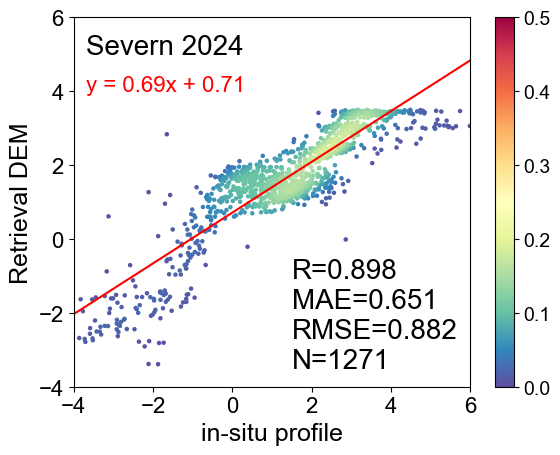

绘图完成！


In [18]:
year  = 2024
path = 'H:\ICESat-2\Region4_map\Solway_map\in_situ\Profile_Solway_2019.shp'
# path = 'H:\ICESat-2\Region4_map\Morecambe_map\in_situ\Porfile_Morecambe_2019.shp'
path = 'H:\ICESat-2\Region4_map\Severn_map\in_situ_profile\profile_severn_2024.shp'
a = gpd.read_file(path)
print(a.columns)
# z = draw_validation_plot2('median_v' ,path, 'UK_DEM_202',1, f'E:/UK_situ/all_{year}a.jpg', f'all {year}', [-4, 6, 2], 0.5)
z = draw_validation_plot('median_v' ,path, 'UK_DEM_202', 1, f'E:/UK_situ/all_{year}a.jpg', f'Severn {year}', [-4, 6, 2],[-4, 6, 2],0.5)

Index(['Unnamed__0', 'distance', 'mean_heigh', 'mean_lon', 'mean_lat', 'OSGM',
       'OH', 'Strip_No', 'b1_FB6', 'b2_FB6', 'b3_FB6', 'b4_FB6', 'b5_FB6',
       'b6_FB6', 'LULC', 'ref_dem', 'geometry'],
      dtype='object')
R=0.105, MAE=181.459, RMSE=1346.165, N=4801


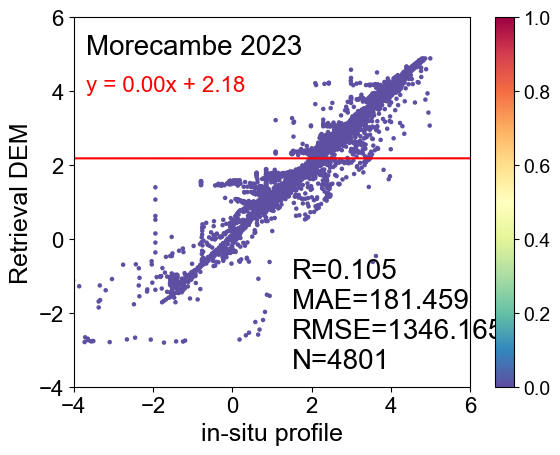

绘图完成！


In [54]:
year = 2023
path = 'H:\ICESat-2\Region4_map\Morecambe_map\A2023\A_Morecambe_30m_2023_new10.shp'
points = gpd.read_file(path)
print(points.columns)
# z = draw_validation_plot('OH' ,path, 'b4_FB6', 1, f'E:/UK_situ/all_{year}a.jpg', f'Morecambe {year}', [-4, 6, 2],[0, 1, 0.2],1), 
# z = draw_validation_plot('OH' ,path, 'ref_dem', 1, f'E:/UK_situ/all_{year}a.jpg', f'Morecambe {year}', [-4, 6, 2],[-4, 6, 2],1), 
z = draw_validation_plot('ref_dem' ,path, 'OH', 1, f'E:/UK_situ/all_{year}a.jpg', f'Morecambe {year}', [-4, 6, 2],[-4, 6, 2],1), 

In [65]:
# path = 'G:\ICESat-2\Region4_map\Region4c_map\A2022\A_Region4c_30m_2022_new10_valid.shp'



def draw_plot(path,  name, vmax):
        
        merged_gdf = gpd.read_file(path)
        z = merged_gdf[['ref_dem', 'OH']]

        mask = (z['OH'] != 0) | (z['ref_dem'] != 6) | (z['ref_dem'] != -999)
        z = z[mask]
        z = z[z != -9999]
        z = z[z != 6]
        z = z[z != 0]
        z = z.dropna()

        x = np.array(z['ref_dem'])  # y_true
        y = np.array(z['OH'])       # y_pred

        R2 = r2_score(x, y)
        MAE = np.mean(np.abs(y - x))
        MSB = np.mean((y - x))
        RMSE = np.sqrt(np.mean((y - x) ** 2))
        num = int(len(x))

        print(f"R² = {R2:.3f}, MAE = {MAE:.3f}, MSB = {MSB:.3f}, RMSE = {RMSE:.3f}, N = {num}")

        # ------------------- 绘图部分 -------------------
        xy = np.vstack([x, y])
        z = gaussian_kde(xy)(xy)

        idx = z.argsort()
        x_sorted, y_sorted, z_sorted = x[idx], y[idx], z[idx]

        fig, ax = plt.subplots()
        textstr = f"R² = {R2:.2f}\nMAE = {MAE:.2f}\nRMSE = {RMSE:.2f}\nN = {num}"

        ax.text(
                0.50, 0.05,
                textstr,
                transform=ax.transAxes,
                fontsize=22,
                verticalalignment='bottom',
                linespacing=1.2   # 默认是 1.0，调大就会加宽行间距
        )

        name = name

        # ax.text(0.05, 0.95, textstr, transform=ax.transAxes, fontsize=18,
        #         verticalalignment='top')
        # ax.text(0.95, 0.05, textstr, transform=ax.transAxes, fontsize=20,
        #         verticalalignment='bottom', horizontalalignment='right')
        ax.text(0.05, 0.87, name, transform=ax.transAxes, fontsize=22,
                verticalalignment='bottom', horizontalalignment='left')

        ax.set_xlabel('Airborne LiDAR DEM', fontsize=18)
        ax.set_ylabel('Refined ICESat-2', fontsize=18)
        ax.plot([-6, 6], [-6, 6], color='gray', linestyle='--', linewidth=0.8, zorder=1)

        sc = ax.scatter(x_sorted, y_sorted, c=z_sorted, vmin=0, vmax=vmax, s=5, cmap='Spectral_r', zorder=2)
        cbar = plt.colorbar(sc)
        cbar.ax.tick_params(labelsize=14) 
        cbar.set_label("Density", fontsize=18)
        ax.set_xlim(-4, 5)
        ax.set_ylim(-4, 5)

        tick_interval = 2
        ticks = np.arange(-4, 5 + tick_interval, tick_interval)
        ax.set_xticks(ticks)
        ax.set_yticks(ticks)

        ax.set_aspect('equal')
        ax.tick_params(axis='both', labelsize=16)

        # plt.savefig(output_dir, dpi=300, bbox_inches='tight')  # 保存图像
        plt.show()
        plt.close()
        
def sample_raster_to_gdf(validation_point_path, raster_path, column_name):
    
    gdf = gpd.read_file(validation_point_path)

    with rasterio.open(raster_path) as src:
        if gdf.crs != src.crs:
            gdf = gdf.to_crs(src.crs)
        coords = [(point.x, point.y) for point in gdf.geometry]
        values = [v[0] if v else None for v in src.sample(coords)]
        gdf[column_name] = values
        
    gdf.to_file(validation_point_path)
    return gdf

R² = 0.901, MAE = 0.250, MSB = 0.095, RMSE = 0.452, N = 4714


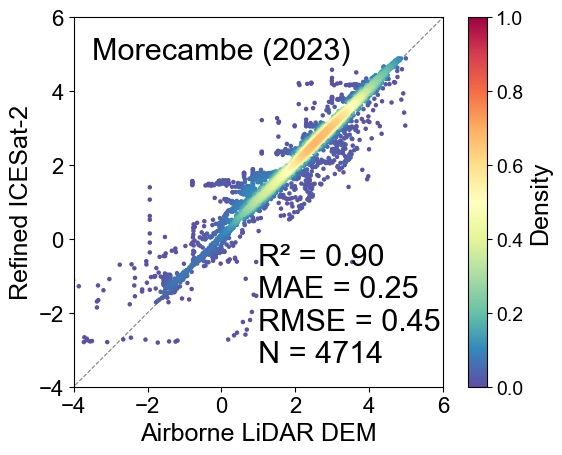

In [107]:
import os
region = 'Region4'
location = 'Morecambe'
location2 = 'Morecambe'

year_list = [2019, 2020, 2021, 2022,2023, 2024]
year_list = [2020, 2021, 2022]
year_list = [2023]
# year_list = [2019]
# year_list = [20]

for year in year_list:
    
    validation_sample_path = 'H:\ICESat-2\Region4_map\Morecambe_map\A2023\A_Morecambe_30m_2023_new10.shp'
    #validation_sample_path = f'H:\ICESat-2\{region}_map\{location}_map\A{year}/A_{location}_30m_{year}_new10_valid_kk.shp'

    # validation_sample_path = f"G:\ICESat-2\{region}_map\{location}_map\A{year}\A_{location}_30m_{year}_new10.shp"
    # ref_dem_path = f"G:\DTM_ref\{location2}\{location2}_{year}\{location2}_masked_{year}.tif"
    # gdf = sample_raster_to_gdf(validation_sample_path, ref_dem_path, 'Ref_dem')
    # plot_output_path = f"H:/ICESat-2/Refined_ICESat_validation4/Swansea/A_Swansea_{year}_new9.png"
    plot_name = f'Morecambe ({year})'
    
    # output_dir = os.path.dirname(plot_output_path)
    # os.makedirs(output_dir, exist_ok=True)
    # plot_name = f'{location} ({year})'
    
    
    
    # gdf = sample_raster_to_gdf(validation_sample_path, ref_dem_path_new, 'Refer_dem_30')
    draw_plot(validation_sample_path, plot_name, 1)

Index(['Unnamed__0', 'distance', 'mean_heigh', 'mean_lon', 'mean_lat', 'OSGM',
       'OH', 'Strip_No', 'b1_FB6', 'b2_FB6', 'b3_FB6', 'b4_FB6', 'b5_FB6',
       'b6_FB6', 'LULC', 'ref_dem', 'geometry'],
      dtype='object')


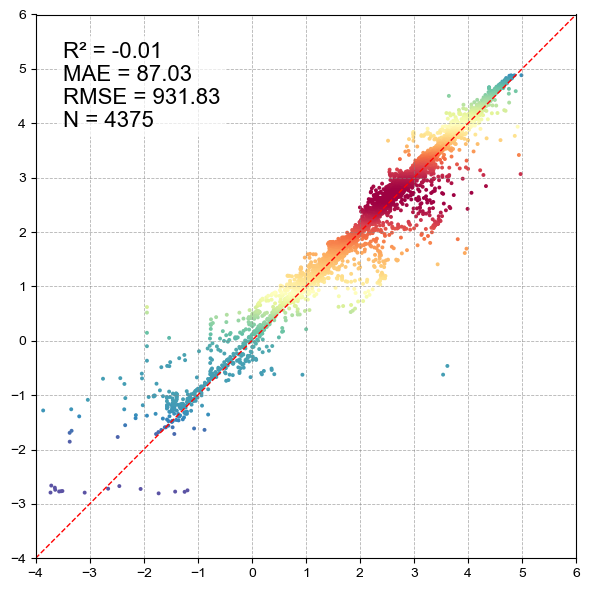

In [108]:
year = 2022
path =  'H:\ICESat-2\Region4_map\Morecambe_map\A2023\A_Morecambe_30m_2023_new10.shp'
# path = f'E:/UK_situ/Shp_data/profile_agg_30m_centerpoint_2024.shp'
a = gpd.read_file(path)
print(a.columns)
ICESAT_Refined(validation_point_path = path,
               refer_name= 'ref_dem',
               band = 'OH',
               std= 1,
               mask_apply = True,  #False True
               oh_mask   = [0],
               Freq_mask = [-1],
               output_to_new_shp=False,
               oh_mask1 =   [0.9, 0.5, 1.4, 2, 3.6, 2.5],
               Freq_mask1 = [1.2, 0.9, 1.6, 2.2, 4, 3],
               rename= '_refined'
               )

In [116]:
b = a[ [ 'distance', 'mean_heigh','mean_lat', 'mean_lon' ,'OSGM', 'OH', 'Strip_No',]]

In [118]:
b['mean_height'] = b['mean_heigh']

C:\Users\minyu\AppData\Local\Temp\ipykernel_35312\2578838787.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  b['mean_height'] = b['mean_heigh']


In [120]:
b.to_csv('H:\ICESat-2\Region4_map\Morecambe_map\A2023\A_Morecambe_30m_2023_new_refined.csv')